<a href="https://colab.research.google.com/github/maysasaad/Alzheimers-Detection/blob/main/nces.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EDS 6340 Team 2

- Akelanda Amadi
- Darshan Reddy Boya
- Julia Bolgova
- Mays Alkwhitar


## National Center for Education Statistics (NCES)

## Introduction

Public schools plays a crucial role in providing educational services for milions of students accross the United States.

The National center for Education Statistics(NCES) offers public information about U.S public schools through their website

https://nces.ed.gov/ccd/schoolsearch/school_list.asp.

This information includes schools ids, links, students enrollment, geographical locations and phone numbers. The project applies web scraping to

collect educational data from 15000 public shools . This information is used for exploratory data analysis and data mining to investigate school

characteristics and student enrollment patterns across the United States.

### Objectives

The main goal of this project is to :

1- Apply web scraping techniques using Python, Requests, and BeautifulSoup to Extract information from individual public school web pages.

2- Build a structured dataset containing information about15,000 U.S. public schools.

### Problem Statement



Provide usful data to help educational steakeholders to understand differences among schools by identifying enrolment pattrens ,

and explore relationships between schools charecters and analyse this information inorder to improve their decissions that contribute

in developing the Educational sector.

### Variable   Description

The dataset consist of 15000 rows represent public schools and 41 (categoricals and numericals) columns

School_Name : Name of the school

NCES_School_ID : Unique NCES identification number

State_School_ID : Identification number assigned by the state.

District_Name : Name of the district

NCES_District_ID : Identification number assigned by the district

State_District_ID :State-assigned district identification number.

Mailing_Address : School mailing address.

Physical_Address : School physical location

Phone : School phone number

School_Type : Classification of the school

Status : Indicates the operational status of the school, showing

whether it is currently open or closed.

Charter : Indicates whether the school is a charter school

County : County where the school is located

Locale : Geographic classification of the school location.

Total_Students : The total number of students enrolled in the school.

Classroom_Teachers : The total number of teachers in the school.

Student_Teacher_Ratio : The number of students for each teacher.

PK_Students : The number of students in pre-k .

KG_Students : The number of students in in KG .

1_Students : The number of students in first grade.

2_Students : The number of students in second grade.

3_Students : The number of students in third grade.

4_Students: The number of students in fourth grade

5_Students: The number of students in fifth grade

6_Students : The number of students in sixth grade

7_Students : The number of students in seventh grade

8_Students : The number of students in eightth grade

9_Students : The number of students in  ninth grade

10_Students : The number of students in tenth grade.

11_Students : The number of students in elevinth grade.

12_Students : The number of students in twelvith grade.

Male_Students: The number of male students.

Female_Students : The number of female students.

American_Indian__Alaska_Native_Students: The number of native  students.

Asian_Students : The number of Asian  students.

Black_Students : The number of Black students.

Hispanic_Students : The number of Hispanic students.

White_Students : The number of white  students.

Native_Hawaiian__Pacific_Islander_Students : The number of

Hawaiian,Pacific,Islander students.

Two_or_More_Races_Students : The number of students who have more than one race.

Ungraded_Students : the number of students enrolled in spesific programs not regular classess

In [ ]:
# Importing libraries
import requests
from bs4 import BeautifulSoup
from io import StringIO
import pandas as pd

Importing Python libraries :

Requests : Send a request to the websites to download Html content.

Beautifulsoup : used to read the downloaded Html and extract information from it .

StringIO : used to treat Html content stored in a string as a file , so Pandas can read Html directly.

Pandas : used to convert the extracted information to Dataframe in order to analyze the information .

These libraries provide the basic tools required to retrieve, extract, and organize educational information from the NCES website.

#### Step 1 — Connect to the NCES website

In [ ]:
import requests

response = requests.get(
    "https://www.google.com",
    timeout=30
)

print("Google status:", response.status_code)

Google status: 200


In [ ]:
import requests

url = "https://nces.ed.gov"

response = requests.get(url, timeout=30)

print("NCES status:", response.status_code)
print("Page length:", len(response.text))

NCES status: 200
Page length: 84183


In [ ]:
# the target website
url = "https://nces.ed.gov/ccd/schoolsearch/school_list.asp"


# set the parameters in a dictionary ( search :indicating that the search should be submitted)
# state refers to Texas the website identified texas with number 48

params = {
    "Search": "1",
    "State": "48"
}
#introduce th client (by creating a dictionary has a key called user agent and value which browser the client is  using)
headers = {"User-Agent": "Mozilla/5.0"}

#Sends a GET request to the website to ask for a web page.

response = requests.get(url, params=params, headers=headers)

# print the respond
print("Status:", response.status_code)

Status: 200


The code established a connection with NCES website to retrive information.

First, identify the website address (URL)

Second ,Set parameters to reach spesific information like state code represented in NCES website, and submit search request.

Third, header : identify the client who wants to communicate to the website

This code ask for a communication between us( clients) and the website and asking for Html page, the out put 200 means that the request was successful and the html page is stored in response.

#### Step 2 — Read the HTML page

In [ ]:
# Parse HTML
soup = BeautifulSoup(response.text, "html.parser")
soup



<!DOCTYPE html>

<html lang="EN">
<head>
<meta charset="utf-8"/>
<meta content="width=device-width, initial-scale=1.0" name="viewport"/>
<title>Search for Public Schools - Search Results</title>
<meta content="Public School Search Results" name="description"/>
<link href="/css/locatorstyles.css" rel="stylesheet" type="text/css"/>
<link href="/inc/schoolsearchtools/schoolSearchToolStyles.css" rel="stylesheet" type="text/css"/>
<script>
	window.name = "NCESExcelTarget";

	function AboutDataPopup()
	{
		window.open('/ccd/commonfiles/aboutdata.asp','AboutDataPopup','width=380,height=390, screenX=0,screenY=0,top=0,left=0,scrollbars=yes,resizable=no');
	}

	function HelpPopup(pagetype)
	{
		window.open('help.asp?page=' + pagetype,'HelpPopup','width=380,height=390, screenX=0,screenY=0,top=0,left=0,scrollbars=yes,resizable=no');
	}
</script>
</head>
<body bgcolor="#ffffff" topmargin="3">
<!-- Start Header -->
<div class="headContents">
<meta content="width=device-width, initial-scale=1" name=

BeautifulSoup is a Python library that helps us read, search, and navigate the downloaded Html.

The Html structure was inspected to identify the school records.Each school's information was grouped inside a

element with the class name resultRow. This allowed us to locate and extract individual school records from the search results.

#### Find the HTML tables and convert them to dataframe

In [ ]:
# 4. Find all HTML tables and print their number
tables = soup.find_all("table")

print("Number of tables:", len(tables))

Number of tables: 5


BeautifulSoup's find_all() method was used to identify all HTML table elements on the webpage. ans it found 5 tables.

In [ ]:
# convert the tables into data frame to read them easly

for i, table in enumerate(tables):

    table_df = pd.read_html(StringIO(str(table)))[0]

    print("Table:", i)
    print("Shape:", table_df.shape)

    display(table_df.head())

Table: 0
Shape: (2, 1)


,0
0,Similar Search
1,"Based on your search for Public Schools, you c..."


Table: 1
Shape: (2, 1)


,0
0,"Based on your search for Public Schools, you c..."
1,Public School Districts | Private Schools | ...


Table: 2
Shape: (1, 5)


,0,1,2,3,4
0,Public School Districts,|,Private Schools,|,Public Libraries


Table: 3
Shape: (2, 1)


,0
0,Download This Data
1,Download Excel FileA data file will be created...


Table: 4
Shape: (3, 4)


,0,1,2,3
0,NaN,Download Excel File,NaN,A data file will be created based on the enter...
1,NaN,NaN,NaN,NaN
2,"Depending on the amount of data, this may take...","Depending on the amount of data, this may take...","Depending on the amount of data, this may take...","Depending on the amount of data, this may take..."


The code converts each table to a dataframe .

For loop used to iterate through all tables .

pd.read_html converted each table into a dataframe .

StringIo treated each table contents as a file like object.

For each table, the program displayed its index number, dimensions (rows and columns), and the first five rows using head().

These tables do not the actual school records.

The school records are stored in HTML elements called div with the class resultRow. We should extract those instead.

#### Finds all the school records on the current webpage

Searches the NCES webpage for the HTML elements that contain individual school records.

In [ ]:
# finds all the school records on the current webpage match the html elements div in the class resultRow

school_rows = soup.find_all("div", class_="resultRow")

print("Number of schools:", len(school_rows))

Number of schools: 15


finds all the school records on the current webpage and counts them. we have 15 schools links

In [ ]:
# display the first school information
print(school_rows[0].prettify())

<div class="resultRow">
 <div>
  1.
 </div>
 <div>
  <a href="school_detail.asp?Search=1&amp;State=48&amp;ID=480735000001" style="font-size: 0.8rem;text-transform: capitalize;">
   a &amp; m cons h s
  </a>
  <br/>
  <span>
   1801 HARVEY MITCHELL PKWY S, COLLEGE STATION, TX 77840
  </span>
 </div>
 <div>
  (979) 764-5500
 </div>
 <div>
  Brazos County
 </div>
 <div>
  2,166
 </div>
 <div>
  9-12
 </div>
</div>



We can extract School name,NCES ID,Address,Phone,County,Students,Grades by using .prettify() method to displays HTML in a readable way.

In [ ]:
# extract information from the first row

school = school_rows[0]
# find the element div
columns = school.find_all("div")

name = school.find("a").get_text(strip=True)

#retrieves the hyperlink address and separates the URL at ID
school_id = school.find("a")["href"].split("ID=")[1]

# Extracts the address text and removes extra space
address = school.find("span").get_text(strip=True)
# extract phone number
phone = columns[2].get_text(strip=True)
# extract county
county = columns[3].get_text(strip=True)
# extract number of students
students = columns[4].get_text(strip=True)
# extract grades information
grades = columns[5].get_text(strip=True)

print("School Name:", name)
print("School ID:", school_id)
print("Address:", address)
print("Phone:", phone)
print("County:", county)
print("Students:", students)
print("Grades:", grades)

School Name: a & m cons h s
School ID: 480735000001
Address: 1801 HARVEY MITCHELL PKWY S, COLLEGE STATION, TX 77840
Phone: (979) 764-5500
County: Brazos County
Students: 2,166
Grades: 9-12


The output of this cell displays first school information like name ,Id, address,phone number,county, students number and grades

In [ ]:
# for loop to extract information from the 15 school in the first page

all_schools = []

for school in school_rows:

    columns = school.find_all("div")

    name = school.find("a").get_text(strip=True)
    school_id = school.find("a")["href"].split("ID=")[1]
    address = school.find("span").get_text(strip=True)
    phone = columns[2].get_text(strip=True)
    county = columns[3].get_text(strip=True)
    students = columns[4].get_text(strip=True)
    grades = columns[5].get_text(strip=True)

    all_schools.append({
        "School_Name": name,
        "NCES_School_ID": school_id,
        "Address": address,
        "Phone": phone,
        "County": county,
        "Students": students,
        "Grades": grades
    })

In [ ]:
all_schools

[{'School_Name': 'a & m cons h s',
  'NCES_School_ID': '480735000001',
  'Address': '1801 HARVEY MITCHELL PKWY S,\xa0COLLEGE STATION,\xa0TX\xa077840',
  'Phone': '(979) 764-5500',
  'County': 'Brazos County',
  'Students': '2,166',
  'Grades': '9-12'},
 {'School_Name': 'a & m consolidated middle',
  'NCES_School_ID': '480735008712',
  'Address': '105 HOLIK DR,\xa0COLLEGE STATION,\xa0TX\xa077840',
  'Phone': '(979) 764-5575',
  'County': 'Brazos County',
  'Students': '681',
  'Grades': '7-8'},
 {'School_Name': 'a b duncan collegiate el',
  'NCES_School_ID': '481944001801',
  'Address': '1011 S 8TH ST,\xa0FLOYDADA,\xa0TX\xa079235',
  'Phone': '(806) 983-5332',
  'County': 'Floyd County',
  'Students': '295',
  'Grades': 'PK-5'},
 {'School_Name': 'a b mcbay el',
  'NCES_School_ID': '483042003424',
  'Address': 'P O BOX 2000,\xa0MEXIA,\xa0TX\xa076667',
  'Phone': '(254) 562-4030',
  'County': 'Limestone County',
  'Students': '498',
  'Grades': 'PK-2'},
 {'School_Name': 'a c blunt middle'

We have a list containing 15 school records, each with seven fields.

In [ ]:
# convert the list to datadrame
df = pd.DataFrame(all_schools)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (15, 7)


,School_Name,NCES_School_ID,Address,Phone,County,Students,Grades
0,a & m cons h s,480735000001,"1801 HARVEY MITCHELL PKWY S, COLLEGE STATION, ...",(979) 764-5500,Brazos County,"2,166",9-12
1,a & m consolidated middle,480735008712,"105 HOLIK DR, COLLEGE STATION, TX 77840",(979) 764-5575,Brazos County,681,7-8
2,a b duncan collegiate el,481944001801,"1011 S 8TH ST, FLOYDADA, TX 79235",(806) 983-5332,Floyd County,295,PK-5
3,a b mcbay el,483042003424,"P O BOX 2000, MEXIA, TX 76667",(254) 562-4030,Limestone County,498,PK-2
4,a c blunt middle,480858000225,"2103 DEMORY LN, ARANSAS PASS, TX 78336",(361) 758-2711,San Patricio County,382,6-8


Convert all_schools list into a dataframe which has 15 raws (all schools in one webpage )and 7 columns( school name,id, address,phone,county,students,Grades)

#### Find the school detail links

We need visits each individual school URL and extracts more detailed information.

In [ ]:
# create a list for all states
state_codes = [ 1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 15, 16,17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28,
                29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40,41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54,
                55, 56 ]

all_schools = []
school_ids = set()

Search for schools in different locations.

In [ ]:
import time
from urllib.parse import urljoin, urlparse, parse_qs

Import 3 functions to deal with uels ; urljoin :helps in combines the websites addressess , urlparse: sperate the ural into different parts .

parse_qs : extract information from urls

In [ ]:
# identify the website
base_url = "https://nces.ed.gov/ccd/schoolsearch/"

# empty list to store all schools
all_schools = []
# prevent dupplicate in school id while collecting information from schools
school_ids = set()
# we need to collect information about 15000schools
target = 15000
print("Target:", target)

Target: 15000


In this code we identify our target website and create a list to store all schools , 15000 schools



In [ ]:
# for loop for each state
for state in state_codes:
# page 1 from the website
    page = 1
# condition since the number of schools less than the target continue
    while len(all_schools) < target:
# build the school link type the state name and the page number
        url = ( base_url + f"school_list.asp?Search=1&State={state}&SchoolPageNum={page}")

        try:
# downloads the page.
            response = requests.get( url, headers=headers, timeout=30 )

# reports an error if the website returns an unsuccessful
            response.raise_for_status()

# reads the downloaded HTML
            soup = BeautifulSoup(response.text, "html.parser")

            page_count = 0

#finds all HTML links that have an href attribute
            for link in soup.find_all("a", href=True):

# gets the web address stored in each link.
                href = link["href"]
# checks whether the link leads to a school's detail page
                if "school_detail.asp" in href:

# combines the current page address with the school's link to create a complete URL.

                    school_url = urljoin(url, href)
# The extracted school ID
                    school_id = parse_qs(urlparse(school_url).query).get("ID", [None])[0]

# checks that we haven't collected this school before
                    if school_id and school_id not in school_ids:
# remembers the ID
                        school_ids.add(school_id)

# store this information(name,id,url ) to the all school list
                        all_schools.append({
                            "School_Name": link.get_text(strip=True),
                            "NCES_School_ID": school_id,
                            "School_URL": school_url
                        })
# increases the number of new schools collected on this page by one
                        page_count += 1

# display howmany schools have been collected

            print(f"State  {state}, Page {page}: " f"{len(all_schools)} schools collected" )

# If no new schools were found on the page, stop visiting this page
            if page_count == 0:
                break
# move to the next page and wait half a second before making another request
            page += 1
            time.sleep(0.5)

# This handles website connection errors.
        except requests.RequestException as e:
            print("Request error:", e)
            break
# stops the state loop when we reach
    if len(all_schools) >= target:
        break



State  1, Page 1: 0 schools collected
State  2, Page 1: 0 schools collected
State  4, Page 1: 0 schools collected
State  5, Page 1: 0 schools collected
State  6, Page 1: 0 schools collected
State  8, Page 1: 0 schools collected
State  9, Page 1: 0 schools collected
State  10, Page 1: 15 schools collected
State  10, Page 2: 30 schools collected
State  10, Page 3: 45 schools collected
State  10, Page 4: 60 schools collected
State  10, Page 5: 75 schools collected
State  10, Page 6: 90 schools collected
State  10, Page 7: 105 schools collected
State  10, Page 8: 120 schools collected
State  10, Page 9: 135 schools collected
State  10, Page 10: 150 schools collected
State  10, Page 11: 165 schools collected
State  10, Page 12: 180 schools collected
State  10, Page 13: 195 schools collected
State  10, Page 14: 210 schools collected
State  10, Page 15: 225 schools collected
State  10, Page 16: 232 schools collected
State  10, Page 17: 232 schools collected
State  11, Page 1: 247 schools coll

In this code , we created a nested loop to collect public school information from NCES website accross multiple states(the outer loop) inner loop (for search results in each state).

used request library to download the webpage and Beautifulsoup to read html content.

searched for each school link and extract information from the link

The program collecting 15,000 unique school links

In [ ]:
schools_df = pd.DataFrame(all_schools[:target])

schools_df.to_csv("school_links_partial.csv", index=False)

print("Saved records:", len(schools_df))

Saved records: 15000


This code created a school dataframe to store 15000 record about each school which contain name ,id and url for each school

In [ ]:
# check shape
print(schools_df.shape)

(15000, 3)


In [ ]:
# display the dataframe
schools_df.head()

,School_Name,NCES_School_ID,School_URL
0,academia antonia alonso,100005300359,https://nces.ed.gov/ccd/schoolsearch/school_de...
1,academy of dover charter school,100001700144,https://nces.ed.gov/ccd/schoolsearch/school_de...
2,allen frear elementary school,100018000038,https://nces.ed.gov/ccd/schoolsearch/school_de...
3,appoquinimink high school,100008000225,https://nces.ed.gov/ccd/schoolsearch/school_de...
4,appoquinimink preschool center,100008000103,https://nces.ed.gov/ccd/schoolsearch/school_de...


We collected information includes school names, NCES identification numbers, and individual school URLs.

#### Download information from school link

In [ ]:
# download the first school information from its link
first_school = schools_df.iloc[0]

response = requests.get(first_school["School_URL"], headers=headers)



This code downloads the detail page for the first school

In [ ]:
# check how many html tables in the first school's page
tables = pd.read_html(StringIO(response.text))

print("Number of tables:", len(tables))

Number of tables: 6


The page has 6 tables

In [ ]:
# examin each table
for i, table in enumerate(tables):
    print("Table number:", i)
    display(table.head())


Table number: 0


,0
0,KG12345678


Table number: 1


,0
0,KG12345678


Table number: 2


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,NaN,KG,1,2,3,4,5,6,7,8,NaN,NaN,NaN,NaN


... (2 outputs left out)

Table number: 4


,0,1,2
0,NaN,Male,Female
1,Students,449,461


Table number: 5


,0,1,2,3,4,5,6,7
0,NaN,American Indian/ Alaska Native,Asian,Black,Hispanic,White,Native Hawaiian/ Pacific Islander,Two or More Races
1,Students,2,2,52,784,65,0,5


Table 0 and 1 have same information the number of kg students ,

In [ ]:
display(tables[0])
display(tables[1])

,0
0,KG12345678


,0
0,KG12345678


This appears to be grade labels joined together, not a student count

Table 2 contains the grade names , Table 3 Contains the actual number of students in each grade. Table 4 contains students by gender, Table 5 contains Students by race.

#### Extracts information from one school

In [ ]:
import re
from io import StringIO

re library searches for specific text patterns in the HTML text. StringIO Allows pandas to read HTML from a string as if it were a file.

In [ ]:
# create a function to download the webpage and read the html tables
def extract_school(row):

# Open the school's detail page download it
    response = requests.get(row["School_URL"], headers=headers)
# reads the html
    soup = BeautifulSoup(response.text, "html.parser")
 # extracts the readable text
    page_text = soup.get_text(" ", strip=True)


# Extract information between two labels
    def get_value(start, end):

        # find the start and end lables and the information in between of them
        pattern = re.escape(start) + r"\s*(.*?)\s+" + re.escape(end)
        # searches for the pattern in the webpage text
        match = re.search(pattern, page_text, re.IGNORECASE)

        if match:
            return match.group(1).strip()
        return None


    # Create a dictionary to store the basic school information
    record = {
        "School_Name": row["School_Name"],
        "NCES_School_ID": row["NCES_School_ID"],
        "State_School_ID": get_value("State School ID:", "District Name:"),
        "District_Name": get_value("District Name:", "NCES District ID:"),
        "NCES_District_ID": get_value("NCES District ID:", "State District ID:"),
        "State_District_ID": get_value("State District ID:", "Mailing Address:"),
        "Mailing_Address": get_value("Mailing Address:", "Physical Address:"),
        "Physical_Address": get_value("Physical Address:", "Phone:"),
        "Phone": get_value("Phone:", "Type:"),
        "School_Type": get_value("Type:", "Status:"),
        "Status": get_value("Status:", "Charter:"),
        "Charter": get_value("Charter:", "Supervisory Union #:"),
        "County": get_value("County:", "Locale:"),
        "Locale": get_value("Locale:", "Total Students:"),
        "Total_Students": get_value("Total Students:", "Classroom Teachers (FTE):"),
        "Classroom_Teachers": get_value("Classroom Teachers (FTE):", "Student/Teacher Ratio:"),
        "Student_Teacher_Ratio": get_value("Student/Teacher Ratio:", "Note:")
    }



# Extract enrollment tables
# extracts the HTML tables and passes the HTML text to Pandas

    tables = pd.read_html(StringIO(response.text))

# checks that at least six tables were found.
    if len(tables) > 5:

# Enrollment by grade
# selects the fourth table and gives the number of columns
        for col in range(1, tables[3].shape[1]):
            # selects the first row and the current column and store it in grade
            grade = str(tables[3].iloc[0, col])

            # extracts the student count from the second row and add the value to the dictionary
            record[grade + "_Students"] = tables[3].iloc[1, col]

# Enrollment by gender
#Selects the columns in the gender table, starting at column 1
        for col in range(1, tables[4].shape[1]):
# Extracts the gender name from the first row
            gender = str(tables[4].iloc[0, col])

# Extracts the students count and adds it to the dictionary
            record[gender + "_Students"] = tables[4].iloc[1, col]

# Enrollment by race
        for col in range(1, tables[5].shape[1]):
# Extracts the race from the first row
            race = str(tables[5].iloc[0, col])
#This changes the slash / and spaces into underscores _
            race = race.replace("/", "_").replace(" ", "_")
#Extracts the student count and saves it in the dictionary
            record[race + "_Students"] = tables[5].iloc[1, col]
# return the dictionary
    return record

Extract_school function : collect information from each school webpage. it gets school record which has id, url requests.get() downloads its webpage. BeautifulSoup() reads the HTML. get_text() extracts the readable text. panda_readhtml() convert the extracted tables into a datafram.

get_value function: searches for information between two labels start , end. searches for the pattern in the webpage text.

Finally, the function returns a dictionary containing all the extracted information for that school.

#### Collecting information from all 15,000 school webpages

In [ ]:
#  import ThreadPoolExecutor

from concurrent.futures import ThreadPoolExecutor, as_completed

# creates an empty list to store the information extracted from all schools
all_records = []

# Define the batch size ,process 100 schools at a time
batch_size = 100

# for loop start from 0 into the length of the dataframe
for start in range(0, len(schools_df), batch_size):

# selects 100 schools from the dataframe
    batch = schools_df.iloc[start:start + batch_size]

# creates a temporary list to store the results from the current batch
    records = []

# parallel processing begins allows up to three school webpages to be processed at the same time.
    with ThreadPoolExecutor(max_workers=3) as executor:

# Submit the school extraction tasks
# Goes through the rows of current batch one by one , row contains the information for one school.
# Run the extract_school() function using this school's information
# store the result in a dictionary called future

        futures = {
                  executor.submit(extract_school, row): row
                  for _, row in batch.iterrows()
        }

# This goes through the submitted tasks as they finish then append the result to the list records and if there is any error print it

        for future in as_completed(futures):
            try:
                records.append(future.result())

            except Exception as e:
                print("Error:", e)

# Add the batch results to the main list
    all_records.extend(records)

    # Save progress after every batch
    pd.DataFrame(all_records).to_csv(
        "df_partial.csv", index=False
    )

    print(
        "Completed:",
        min(start + batch_size, len(schools_df)),
        "of",
        len(schools_df),
        "| Successfully collected:",
        len(all_records)
    )


Completed: 100 of 15000 | Successfully collected: 100
Completed: 200 of 15000 | Successfully collected: 200
Completed: 300 of 15000 | Successfully collected: 300
Completed: 400 of 15000 | Successfully collected: 400
Completed: 500 of 15000 | Successfully collected: 500
Completed: 600 of 15000 | Successfully collected: 600
Completed: 700 of 15000 | Successfully collected: 700
Completed: 800 of 15000 | Successfully collected: 800
Completed: 900 of 15000 | Successfully collected: 900
Completed: 1000 of 15000 | Successfully collected: 1000
Completed: 1100 of 15000 | Successfully collected: 1100
Completed: 1200 of 15000 | Successfully collected: 1200
Completed: 1300 of 15000 | Successfully collected: 1300
Completed: 1400 of 15000 | Successfully collected: 1400
Completed: 1500 of 15000 | Successfully collected: 1500
Completed: 1600 of 15000 | Successfully collected: 1600
Completed: 1700 of 15000 | Successfully collected: 1700
Completed: 1800 of 15000 | Successfully collected: 1800
Completed:

ThreadPoolExecutor : Allows Python to work on multiple school webpages at the same time instead of waiting for each webpage to finish before starting the next one.

as_completed : Allows Python to collect each school's result as soon as its task finishes.

The goal of these libraries is to save time.

The following code was used to automate the extraction of school information from multiple NCES webpages. Instead of processing schools one at a time, the code divides the school dataset into batches of 100 records and uses parallel processing to retrieve information from multiple webpages

The print() statement displays the number of schools processed and the number of successfully collected records after each batch.

#### The final dataset

In [ ]:
# Create final dataset
df = pd.DataFrame(all_records)

df.to_csv("Shools_df.csv", index=False)

print("Final dataset:", df.shape)

Final dataset: (15000, 41)


In [32]:
# read and display the data set
df = pd.read_csv("Shools_df.csv")

# Display the first five rows
display(df.head())

,School_Name,NCES_School_ID,State_School_ID,District_Name,NCES_District_ID,State_District_ID,Mailing_Address,Physical_Address,Phone,School_Type,...,Hispanic_Students,White_Students,Native_Hawaiian__Pacific_Islander_Students,Two_or_More_Races_Students,9_Students,10_Students,11_Students,12_Students,PK_Students,Ungraded_Students
0,academia antonia alonso,100005300359,DE-9605-4045,Academia Antonia Alonso,1000053,DE-9605,"300 North Wakefield Drive Newark DE, 19702","300 North Wakefield Drive Newark DE, 19702",(302) 351-8200,Regular school,...,784,65,0,5,NaN,NaN,NaN,NaN,NaN,NaN
1,academy of dover charter school,100001700144,DE-85-584,Academy Of Dover Charter School,1000017,DE-85,"104 Saulsbury Road Dover DE, 19904","104 Saulsbury Road Dover DE, 19904",(302) 674-0684,Regular school,...,74,42,0,20,NaN,NaN,NaN,NaN,NaN,NaN
2,allen frear elementary school,100018000038,DE-10-610,Caesar Rodney School District,1000180,DE-10,"238 Sorghum Mill Road Camden DE, 19934","238 Sorghum Mill Road Camden DE, 19934",(302) 697-3279,Regular school,...,49,256,1,51,NaN,NaN,NaN,NaN,NaN,NaN
3,appoquinimink high school,100008000225,DE-29-24,Appoquinimink School District,1000080,DE-29,"1080 Bunker Hill Road Middletown DE, 19709","1080 Bunker Hill Road Middletown DE, 19709",(302) 449-3840,Regular school,...,110,608,3,51,299,336,321,401,NaN,NaN
4,appoquinimink preschool center,100008000103,DE-29-13,Appoquinimink School District,1000080,DE-29,"502 South Broad Street Middletown DE, 19709 –1196","502 South Broad Street Middletown DE, 19709 –1196",(302) 376-4400,Special education school,...,13,75,0,6,NaN,NaN,NaN,NaN,150,NaN


The final dataset contained 15,000 school records and 41 variables.
Each row represents one public school, while each column represents a specific school characteristic or enrollment variable.


**PART-02 **

In [33]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

**Observations:** Libraries loaded. pandas/numpy for data work, matplotlib/seaborn for plots, and scikit-learn only for scaling at the end.

In [35]:
import pandas as pd

DATA_PATH = 'Shools_df.csv'

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print('Shape:', df.shape)
df.head()

Shape: (15000, 41)


,School_Name,NCES_School_ID,State_School_ID,District_Name,NCES_District_ID,State_District_ID,Mailing_Address,Physical_Address,Phone,School_Type,Status,Charter,County,Locale,Total_Students,Classroom_Teachers,Student_Teacher_Ratio,KG_Students,1_Students,2_Students,3_Students,4_Students,5_Students,6_Students,7_Students,8_Students,Male_Students,Female_Students,American_Indian__Alaska_Native_Students,Asian_Students,Black_Students,Hispanic_Students,White_Students,Native_Hawaiian__Pacific_Islander_Students,Two_or_More_Races_Students,9_Students,10_Students,11_Students,12_Students,PK_Students,Ungraded_Students
0,academia antonia alonso,100005300359,DE-9605-4045,Academia Antonia Alonso,1000053,DE-9605,"300 North Wakefield Drive Newark DE, 19702","300 North Wakefield Drive Newark DE, 19702",(302) 351-8200,Regular school,Open,Yes,New Castle County,"Suburban, Large (21)",910,50.00,18.20,109,92,106,122,113,89,108,101,70,449,461,2,2,52,784,65,0,5,NaN,NaN,NaN,NaN,NaN,NaN
1,academy of dover charter school,100001700144,DE-85-584,Academy Of Dover Charter School,1000017,DE-85,"104 Saulsbury Road Dover DE, 19904","104 Saulsbury Road Dover DE, 19904",(302) 674-0684,Regular school,Open,Yes,Kent County,"City, Small (13)",443,29.00,15.28,47,59,68,62,57,44,44,46,16,221,222,1,1,305,74,42,0,20,NaN,NaN,NaN,NaN,NaN,NaN
2,allen frear elementary school,100018000038,DE-10-610,Caesar Rodney School District,1000180,DE-10,"238 Sorghum Mill Road Camden DE, 19934","238 Sorghum Mill Road Camden DE, 19934",(302) 697-3279,Regular school,Open,No,Kent County,"Suburban, Midsize (22)",504,41.00,12.29,NaN,92,89,108,117,98,NaN,NaN,NaN,262,242,2,30,115,49,256,1,51,NaN,NaN,NaN,NaN,NaN,NaN
3,appoquinimink high school,100008000225,DE-29-24,Appoquinimink School District,1000080,DE-29,"1080 Bunker Hill Road Middletown DE, 19709","1080 Bunker Hill Road Middletown DE, 19709",(302) 449-3840,Regular school,Open,No,New Castle County,"Rural, Fringe (41)","1,357",89.00,15.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,710,647,8,155,422,110,608,3,51,299,336,321,401,NaN,NaN
4,appoquinimink preschool center,100008000103,DE-29-13,Appoquinimink School District,1000080,DE-29,"502 South Broad Street Middletown DE, 19709 –1196","502 South Broad Street Middletown DE, 19709 –1196",(302) 376-4400,Special education school,Open,No,New Castle County,"Town, Fringe (31)",150,20.00,7.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,106,44,0,13,43,13,75,0,6,NaN,NaN,NaN,NaN,150,NaN


**Observations:** The raw file has 15,000 rows and 41 columns, which meets the project minimum (15,000 rows, 7 columns). We can already see messy bits: lowercase school names, an address with a stray dash (`19711 –8017`), and NaNs in the grade columns.

## 4. Exploratory Data Analysis


### A) Basic Data Exploration

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 41 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   School_Name                                 15000 non-null  object 
 1   NCES_School_ID                              15000 non-null  int64  
 2   State_School_ID                             15000 non-null  object 
 3   District_Name                               15000 non-null  object 
 4   NCES_District_ID                            15000 non-null  int64  
 5   State_District_ID                           15000 non-null  object 
 6   Mailing_Address                             15000 non-null  object 
 7   Physical_Address                            15000 non-null  object 
 8   Phone                                       15000 non-null  object 
 9   School_Type                                 15000 non-null  object 
 10  Status    

**Observations:** Almost every column loads as text (`object`/`str`), including enrollment and teacher counts. Only the two NCES IDs and `Ungraded_Students` were read as numbers. Numeric columns stored as text will break any math or plotting, so they need fixing.

In [37]:
# Which columns are NOT numeric, and which of those should be?
numeric_cols = df.select_dtypes(include='number').columns
non_numeric = [c for c in df.columns if c not in numeric_cols]
should_be_numeric = [c for c in non_numeric if c.endswith('_Students') or c in ['Classroom_Teachers', 'Student_Teacher_Ratio']]
print('Numeric columns       :', len(numeric_cols))
print('Text columns          :', len(non_numeric))
print('Text but should be num:', len(should_be_numeric))
should_be_numeric[:6]

Numeric columns       : 3
Text columns          : 38
Text but should be num: 26


['Total_Students',
 'Classroom_Teachers',
 'Student_Teacher_Ratio',
 'KG_Students',
 '1_Students',
 '2_Students']

**Observations:** Of 41 columns, only 3 are numeric. 26 of the text columns actually hold counts (students per grade, race, gender, teachers, ratio). Something inside these columns is stopping pandas from reading them as numbers.

In [38]:
# Special reporting symbols hiding inside the columns
MARKERS = ['†', '‡', '–']
marker_counts = df.apply(lambda col: col.isin(MARKERS).sum())
marker_counts[marker_counts > 0].sort_values(ascending=False).head(12)

,0
Student_Teacher_Ratio,1077
Total_Students,491
Classroom_Teachers,335
Locale,254
County,254
Native_Hawaiian__Pacific_Islander_Students,18
American_Indian__Alaska_Native_Students,17
White_Students,10
Female_Students,10
Asian_Students,10


**Observations:** Found the cause: the symbols `†`, `‡` and `–`. These are NCES reporting codes (not applicable / standard not met / missing), not real data. They appear most in `Student_Teacher_Ratio` (1,077), `Total_Students` (491) and `Classroom_Teachers` (335). `County` and `Locale` also contain 254 `†` each, so the same fix applies to text columns.

In [39]:
# Cardinality and a few sample categories
cat_cols = ['School_Type', 'Status', 'Charter', 'Locale']
for c in cat_cols:
    print(f'--- {c} ({df[c].nunique()} unique) ---')
    print(df[c].value_counts(dropna=False).to_string(), '\n')

--- School_Type (4 unique) ---
School_Type
Regular school              13587
Other/alternative school      772
Special education school      515
Vocational school             126 

--- Status (6 unique) ---
Status
Open              14726
New                 138
Added                86
Future               41
Reopened              8
Changed Agency        1 

--- Charter (2 unique) ---
Charter
No     13593
Yes     1407 

--- Locale (13 unique) ---
Locale
Suburban, Large (21)      5054
City, Large (11)          1804
Rural, Distant (42)       1727
Rural, Fringe (41)        1407
City, Small (13)          1126
Town, Distant (32)         899
City, Midsize (12)         815
Rural, Remote (43)         577
Suburban, Midsize (22)     441
Town, Fringe (31)          320
Town, Remote (33)          314
Suburban, Small (23)       262
†                          254 



**Observations:** Categories are fairly clean: 4 school types (95% regular), 2 charter values, and 6 status values (almost all `Open`). `Locale` has 13 values, but one of them is the `†` marker, so there are really 12 locale categories.

### B) Data Cleaning, Univariate / Bivariate / Multivariate Analysis

#### B1. Standardise column names

In [40]:
# lower-case, no double underscores, and no names that start with a digit
df.columns = df.columns.str.strip().str.lower().str.replace('__', '_')

rename_map = {f'{g}_students': f'grade_{g}_students' for g in range(1, 13)}
rename_map.update({
    'american_indian_alaska_native_students': 'aian_students',
    'native_hawaiian_pacific_islander_students': 'nhpi_students',
    'two_or_more_races_students': 'multiracial_students',
})
df = df.rename(columns=rename_map)
list(df.columns)

['school_name',
 'nces_school_id',
 'state_school_id',
 'district_name',
 'nces_district_id',
 'state_district_id',
 'mailing_address',
 'physical_address',
 'phone',
 'school_type',
 'status',
 'charter',
 'county',
 'locale',
 'total_students',
 'classroom_teachers',
 'student_teacher_ratio',
 'kg_students',
 'grade_1_students',
 'grade_2_students',
 'grade_3_students',
 'grade_4_students',
 'grade_5_students',
 'grade_6_students',
 'grade_7_students',
 'grade_8_students',
 'male_students',
 'female_students',
 'aian_students',
 'asian_students',
 'black_students',
 'hispanic_students',
 'white_students',
 'nhpi_students',
 'multiracial_students',
 'grade_9_students',
 'grade_10_students',
 'grade_11_students',
 'grade_12_students',
 'pk_students',
 'ungraded_students']

**Observations:** Column names are now lowercase snake_case. Names starting with digits (`1_Students`) became `grade_1_students` so they work as normal Python names, and the very long race columns got short names (`aian_`, `nhpi_`, `multiracial_`).

#### B2. Replace reporting symbols with NaN and fix data types

In [41]:
df = df.replace(MARKERS, np.nan)    # † ‡ – are not real values

count_cols = [c for c in df.columns if c.endswith('_students') or c in ['classroom_teachers', 'student_teacher_ratio']]
for c in count_cols:
    # "1,357" -> 1357 ; anything unparseable becomes NaN
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', ''), errors='coerce')

print('Columns converted to numeric:', len(count_cols))
df[['total_students', 'classroom_teachers', 'student_teacher_ratio']].dtypes

Columns converted to numeric: 27


,0
total_students,float64
classroom_teachers,float64
student_teacher_ratio,float64


**Observations:** All markers are now proper `NaN`, and the 27 count columns are numeric (`float64`). Thousand separators like `1,357` were handled too. Now we can do math on them and see the missing values properly.

#### B3. Clean text columns

In [42]:
def title_case(s):
    # .title() turns "mary's" into "Mary'S", so fix that afterwards
    return s.str.title().str.replace(r"'S\b", "'s", regex=True)

for c in ['school_name', 'district_name', 'county']:
    df[c] = title_case(df[c].str.strip().str.replace(r'\s+', ' ', regex=True))

# addresses: collapse spaces and fix the odd " –8017" zip+4 dash
for c in ['mailing_address', 'physical_address']:
    df[c] = (df[c].str.replace(r'\s+', ' ', regex=True)
                  .str.replace(r' ?[–—-] ?(\d{4})$', r'-\1', regex=True)
                  .str.strip())

df[['school_name', 'district_name', 'county', 'physical_address']].head()

,school_name,district_name,county,physical_address
0,Academia Antonia Alonso,Academia Antonia Alonso,New Castle County,"300 North Wakefield Drive Newark DE, 19702"
1,Academy Of Dover Charter School,Academy Of Dover Charter School,Kent County,"104 Saulsbury Road Dover DE, 19904"
2,Allen Frear Elementary School,Caesar Rodney School District,Kent County,"238 Sorghum Mill Road Camden DE, 19934"
3,Appoquinimink High School,Appoquinimink School District,New Castle County,"1080 Bunker Hill Road Middletown DE, 19709"
4,Appoquinimink Preschool Center,Appoquinimink School District,New Castle County,"502 South Broad Street Middletown DE, 19709-1196"


**Observations:** Names are consistent title case (`Academy Of Dover Charter School`), extra spaces are gone, and the zip+4 dash is fixed (`19711-8017`). This also stops the same name written two ways from being counted as two categories.

#### B4. Missing values

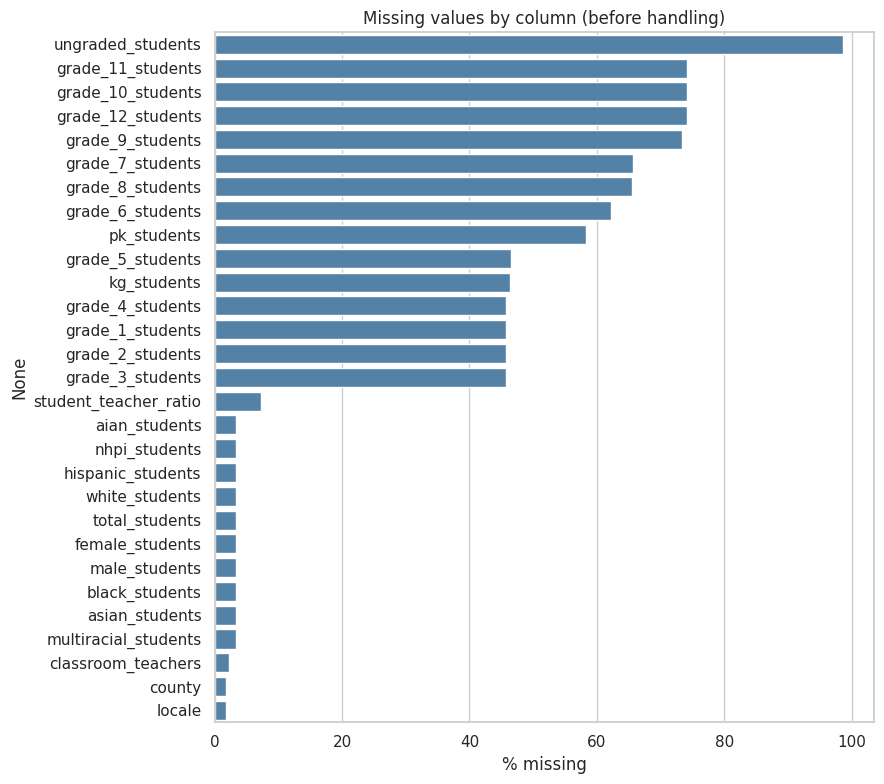

,missing,pct
ungraded_students,14793,98.6
grade_11_students,11132,74.2
grade_10_students,11133,74.2
grade_12_students,11135,74.2
grade_9_students,10997,73.3
grade_7_students,9859,65.7
grade_8_students,9844,65.6
grade_6_students,9341,62.3
pk_students,8750,58.3
grade_5_students,6976,46.5


In [43]:
missing = df.isna().sum().to_frame('missing')
missing['pct'] = (missing['missing'] / len(df) * 100).round(1)
missing = missing[missing['missing'] > 0].sort_values('pct', ascending=False)

plt.figure(figsize=(9, 8))
sns.barplot(x=missing['pct'], y=missing.index, color='steelblue')
plt.xlabel('% missing'); plt.title('Missing values by column (before handling)')
plt.tight_layout(); plt.show()
missing.head(10)

**Observations:** Grade columns have the highest missing percentages (e.g. 74% for grades 10 to 12, 58% for PK, 99% for ungraded). That is expected: an elementary school has no 11th graders, so those blanks are structural zeros, not lost data. The ones that really matter are the missing totals, teachers, ratio and demographics.

**How we will treat the missing values**
- **Grade columns** (`kg`, `grade_1` … `grade_12`, `pk`, `ungraded`): a blank means the school does not teach that grade, so it is a real zero, not unknown. We fill with 0.
- **`total_students` missing or 0:** the school has no usable enrollment, so it can't be analysed. We drop these rows.
- **`classroom_teachers` = 0 while students > 0:** impossible, so we treat it as unknown and impute.
- **Demographic counts** (gender/race): rows with no breakdown are dropped.
- **`county`:** fill from other schools in the same district, else `Unknown`.

In [44]:
n_start = len(df)

# 1) Future schools have no students yet
df = df[df['status'] != 'Future']

# 2) No usable enrollment -> drop
no_enrollment = df['total_students'].isna() | (df['total_students'] == 0)
print('Rows with missing/zero enrollment:', no_enrollment.sum())
df = df[~no_enrollment].copy()

# 3) No demographic breakdown -> drop
demo_cols = ['male_students', 'female_students', 'aian_students', 'asian_students', 'black_students',
             'hispanic_students', 'white_students', 'nhpi_students', 'multiracial_students']
no_demo = df[demo_cols].isna().any(axis=1)
print('Rows with missing demographics   :', no_demo.sum())
df = df[~no_demo].copy()

print(f'Rows: {n_start} -> {len(df)}  ({n_start - len(df)} removed)')

Rows with missing/zero enrollment: 1051
Rows with missing demographics   : 12
Rows: 15000 -> 13896  (1104 removed)


**Observations:** Removed 1,104 rows (7.4%): 41 `Future` schools (not open yet), 1,051 with missing or zero enrollment, and 12 with no demographic breakdown. Without enrollment a school can't be analysed. We tried recovering it from grade and gender sums, but those were empty too. A side effect: nearly all `New`, `Added` and `Reopened` schools were removed because they had no enrollment reported, so almost every remaining school has status `Open`.

In [45]:
# Teachers: 0 teachers with students is impossible -> unknown
df.loc[df['classroom_teachers'] == 0, 'classroom_teachers'] = np.nan

# The ratio is just students / teachers, so recompute it to keep everything consistent
df['student_teacher_ratio'] = df['total_students'] / df['classroom_teachers']

# Impute missing ratios with the median of the same school type, then back-fill the teacher count
df['ratio_imputed'] = df['student_teacher_ratio'].isna()
type_median = df.groupby('school_type')['student_teacher_ratio'].transform('median')
df['student_teacher_ratio'] = df['student_teacher_ratio'].fillna(type_median)
df['classroom_teachers'] = df['classroom_teachers'].fillna((df['total_students'] / df['student_teacher_ratio']).round(1))

print('Ratios imputed:', df['ratio_imputed'].sum())
df[['total_students', 'classroom_teachers', 'student_teacher_ratio']].isna().sum()

Ratios imputed: 264


,0
total_students,0
classroom_teachers,0
student_teacher_ratio,0


**Observations:** A school can't have students and zero teachers, so those zeros were treated as unknown. The ratio was recomputed as students / teachers, which keeps all three columns consistent. 264 schools had no usable ratio and got the median ratio of their school type, with the teacher count back-filled. They are marked in `ratio_imputed` so they can be excluded later if needed. No missing values remain in the three core columns.

In [46]:
# Grades a school does not teach -> 0
grade_cols = ['pk_students', 'kg_students'] + [f'grade_{g}_students' for g in range(1, 13)] + ['ungraded_students']
df[grade_cols] = df[grade_cols].fillna(0)

# County / locale: use the most common value within the same district, else 'Unknown'
def mode_or_nan(s):
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan

for c in ['county', 'locale']:
    df[c] = df[c].fillna(df.groupby('nces_district_id')[c].transform(mode_or_nan)).fillna('Unknown')

print('Missing values left:', df.isna().sum().sum())

Missing values left: 0


**Observations:** Grade blanks were filled with 0 (the school does not teach that grade) and county/locale were filled from other schools in the same district. The dataset now has zero missing values.

#### B5. Duplicates

In [47]:
print('Fully duplicated rows        :', df.duplicated().sum())
print('Duplicated NCES school IDs    :', df['nces_school_id'].duplicated().sum())

same_name_addr = df[df.duplicated(['school_name', 'physical_address'], keep=False)]
print('Rows sharing name + address   :', len(same_name_addr))
same_name_addr[['school_name', 'physical_address', 'nces_school_id', 'total_students']].sort_values('school_name').head(8)

Fully duplicated rows        : 0
Duplicated NCES school IDs    : 0
Rows sharing name + address   : 0


,school_name,physical_address,nces_school_id,total_students


In [48]:
# Do the parts add up to the total?
df['grade_sum']  = df[grade_cols].sum(axis=1)
df['gender_sum'] = df[['male_students', 'female_students']].sum(axis=1)
df['race_sum']   = df[['aian_students', 'asian_students', 'black_students', 'hispanic_students',
                       'white_students', 'nhpi_students', 'multiracial_students']].sum(axis=1)

checks = pd.DataFrame({
    'mismatch_rows': [(df[c] != df['total_students']).sum() for c in ['grade_sum', 'gender_sum', 'race_sum']],
    'mismatch_pct':  [(df[c] != df['total_students']).mean() * 100 for c in ['grade_sum', 'gender_sum', 'race_sum']],
}, index=['grades vs total', 'gender vs total', 'race vs total']).round(1)

# flag, don't drop: small mismatches are normal rounding/suppression in the source
df['parts_mismatch'] = (df['gender_sum'] != df['total_students']) | (df['race_sum'] != df['total_students'])
checks

,mismatch_rows,mismatch_pct
grades vs total,0,0.0
gender vs total,381,2.7
race vs total,381,2.7


**Observations:** Grade counts add up to the total for every school (0 mismatches), which is a good sign for data quality. Gender and race counts differ from the total in 381 schools (2.7%), likely from rounding or suppression in the source. We flagged those in `parts_mismatch` instead of dropping them, since the difference is small.

#### B7. Outliers

                       lower   upper  n_outliers  pct     max
total_students        -348.0  1372.0       927.0  6.7  9952.0
classroom_teachers     -18.3    88.1       702.0  5.1   551.5
student_teacher_ratio    6.0    23.3       842.0  6.1   917.0


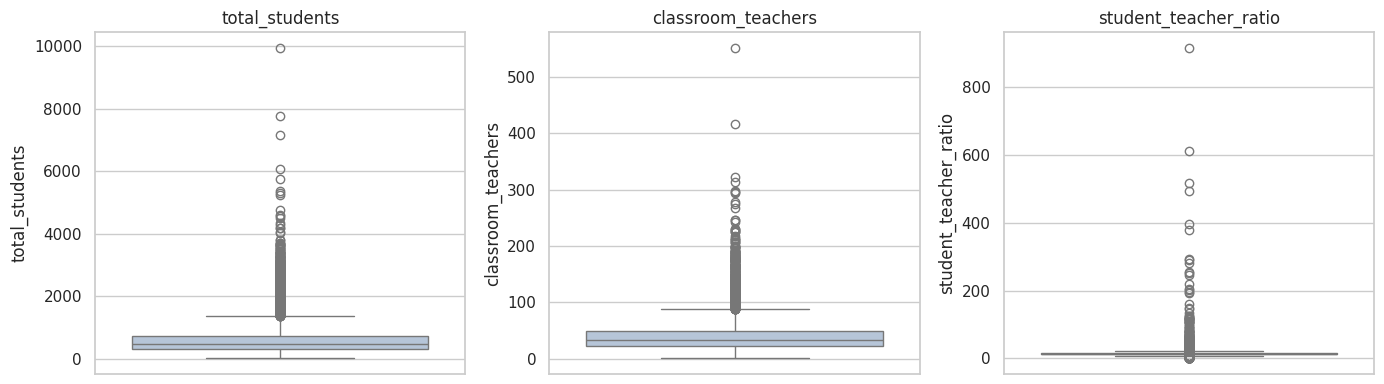

In [49]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'lower': low, 'upper': high, 'n_outliers': ((s < low) | (s > high)).sum(),
                      'pct': ((s < low) | (s > high)).mean() * 100, 'max': s.max()})

out_cols = ['total_students', 'classroom_teachers', 'student_teacher_ratio']
print(pd.DataFrame({c: iqr_outliers(df[c]) for c in out_cols}).T.round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, out_cols):
    sns.boxplot(y=df[c], ax=ax, color='lightsteelblue'); ax.set_title(c)
plt.tight_layout(); plt.show()

**Observations:** About 6 to 7% of schools are outliers by the IQR rule in each column. The largest school has 9,952 students and the most extreme ratio is 917 students per teacher, far above anything realistic. The boxplots show a long right tail in all three columns.

In [50]:
# Big schools and big staffs are real, so we keep them (and log-transform later).
# But extreme student-teacher ratios are mostly data quirks (e.g. tiny teacher counts) -> cap at 1st/99th percentile.
low, high = df['student_teacher_ratio'].quantile([0.01, 0.99])
df['ratio_capped'] = df['student_teacher_ratio'].clip(low, high)
print(f'Ratio capped to [{low:.1f}, {high:.1f}]')
df[['student_teacher_ratio', 'ratio_capped']].describe().round(1)

Ratio capped to [4.6, 40.6]


,student_teacher_ratio,ratio_capped
count,13896.0,13896.0
mean,15.7,15.1
std,15.1,4.8
min,0.1,4.6
25%,12.5,12.5
50%,14.5,14.5
75%,16.8,16.8
max,917.0,40.6


**Observations:** Big schools are real, so we keep them. But extreme ratios come from tiny teacher counts, so the ratio is capped at the 1st and 99th percentile (4.6 to 40.6) in `ratio_capped`. This reduced the standard deviation from 15.1 to 4.8 and the max from 917 to 40.6, while the median stayed at 14.5, so typical schools were not changed.

#### B8. Data wrangling and feature engineering

In [51]:
# Locale: "City, Large (11)" -> type / size / code
loc = df['locale'].str.extract(r'^(?P<locale_type>\w+), (?P<locale_size>\w+) \((?P<locale_code>\d+)\)$')
df['locale_type'] = loc['locale_type'].fillna('Unknown')
df['locale_size'] = loc['locale_size'].fillna('Unknown')

# State and ZIP from the physical address ("... Dover DE, 19904")
addr = df['physical_address'].str.extract(r'\b(?P<state>[A-Z]{2}),\s*(?P<zip5>\d{5})')
df['state'] = addr['state']
df['zip5'] = addr['zip5']
print('State from address vs ID prefix disagree:', (df['state'] != df['state_school_id'].str[:2]).sum(), 'rows')

# Does the mailing address differ from the physical one?
df['mailing_differs'] = (df['mailing_address'].str.upper() != df['physical_address'].str.upper()).astype(int)

df[['locale_type', 'locale_size', 'state', 'zip5', 'mailing_differs']].head()

State from address vs ID prefix disagree: 2 rows


,locale_type,locale_size,state,zip5,mailing_differs
0,Suburban,Large,DE,19702,0
1,City,Small,DE,19904,0
2,Suburban,Midsize,DE,19934,0
3,Rural,Fringe,DE,19709,0
4,Town,Fringe,DE,19709,0


In [52]:
# Locale: "City, Large (11)" -> type / size / code
loc = df['locale'].str.extract(r'^(?P<locale_type>\w+), (?P<locale_size>\w+) \((?P<locale_code>\d+)\)$')
df['locale_type'] = loc['locale_type'].fillna('Unknown')
df['locale_size'] = loc['locale_size'].fillna('Unknown')

# State and ZIP from the physical address ("... Dover DE, 19904")
addr = df['physical_address'].str.extract(r'\b(?P<state>[A-Z]{2}),\s*(?P<zip5>\d{5})')
df['state'] = addr['state']
df['zip5'] = addr['zip5']
print('State from address vs ID prefix disagree:', (df['state'] != df['state_school_id'].str[:2]).sum(), 'rows')

# Does the mailing address differ from the physical one?
df['mailing_differs'] = (df['mailing_address'].str.upper() != df['physical_address'].str.upper()).astype(int)

df[['locale_type', 'locale_size', 'state', 'zip5', 'mailing_differs']].head()

State from address vs ID prefix disagree: 2 rows


,locale_type,locale_size,state,zip5,mailing_differs
0,Suburban,Large,DE,19702,0
1,City,Small,DE,19904,0
2,Suburban,Midsize,DE,19934,0
3,Rural,Fringe,DE,19709,0
4,Town,Fringe,DE,19709,0


**Observations:** `Locale` was split into a type (City/Suburban/Town/Rural) and a size (Small/Midsize/Large/Fringe/Distant/Remote). State and ZIP were pulled from the physical address. Two schools have an address state that doesn't match their state ID prefix (they show up as 1 MD and 1 OR school); we trust the physical address.

In [53]:
# School level, based on which grades actually have students
elem = df[['kg_students'] + [f'grade_{g}_students' for g in range(1, 6)]].sum(axis=1) > 0
mid  = df[[f'grade_{g}_students' for g in range(6, 9)]].sum(axis=1) > 0
high = df[[f'grade_{g}_students' for g in range(9, 13)]].sum(axis=1) > 0

df['school_level'] = np.select(
    [elem & ~mid & ~high, mid & ~elem & ~high, high & ~elem & ~mid, elem & mid & ~high, mid & high & ~elem],
    ['Elementary', 'Middle', 'High', 'Elementary-Middle', 'Middle-High'],
    default='Other / Combined')

df['has_pk'] = (df['pk_students'] > 0).astype(int)
df['charter_bin'] = (df['charter'] == 'Yes').astype(int)
df['enrollment_size'] = pd.cut(df['total_students'], [0, 200, 500, 1000, 2000, np.inf],
                               labels=['<200', '200-500', '500-1000', '1000-2000', '2000+'])
df['schools_in_district'] = df.groupby('nces_district_id')['nces_school_id'].transform('count')

df['school_level'].value_counts()

,count
school_level,
Elementary,5697
Elementary-Middle,2413
High,2213
Middle,1986
Other / Combined,817
Middle-High,770


**Observations:** Created `school_level` from the grades with students. Elementary schools are the largest group (5,696), followed by Elementary-Middle (2,414) and High (2,213). Also added `has_pk`, `charter_bin`, `enrollment_size` and `schools_in_district` as new features.

In [54]:
# Demographic shares (counts are hard to compare across big and small schools)
t = df['total_students']
df['pct_female']   = (df['female_students'] / t * 100).clip(0, 100)
df['pct_white']    = (df['white_students'] / t * 100).clip(0, 100)
df['pct_black']    = (df['black_students'] / t * 100).clip(0, 100)
df['pct_hispanic'] = (df['hispanic_students'] / t * 100).clip(0, 100)
df['pct_asian']    = (df['asian_students'] / t * 100).clip(0, 100)
df['pct_other']    = ((df['aian_students'] + df['nhpi_students'] + df['multiracial_students']) / t * 100).clip(0, 100)

df[['pct_female', 'pct_white', 'pct_black', 'pct_hispanic', 'pct_asian', 'pct_other']].describe().round(1)

,pct_female,pct_white,pct_black,pct_hispanic,pct_asian,pct_other
count,13896.0,13896.0,13896.0,13896.0,13896.0,13896.0
mean,48.1,44.7,21.7,24.2,3.3,6.0
std,6.9,32.0,26.8,23.4,7.4,8.0
min,0.0,0.0,0.0,0.0,0.0,0.0
25%,46.5,13.0,1.7,7.0,0.2,2.5
50%,48.5,44.5,9.5,15.9,0.9,4.6
75%,50.3,74.0,32.1,33.5,2.9,7.0
max,100.0,100.0,100.0,100.0,84.2,100.0


**Observations:** Counts were converted into percentages so big and small schools can be compared. On average schools are 45% White, 24% Hispanic, 22% Black, 3% Asian and 48% female. The wide standard deviations (e.g. 32 for White) show schools are quite segregated by race in this data, with many near 0% or near 100%.

#### B9. Distribution and skewness

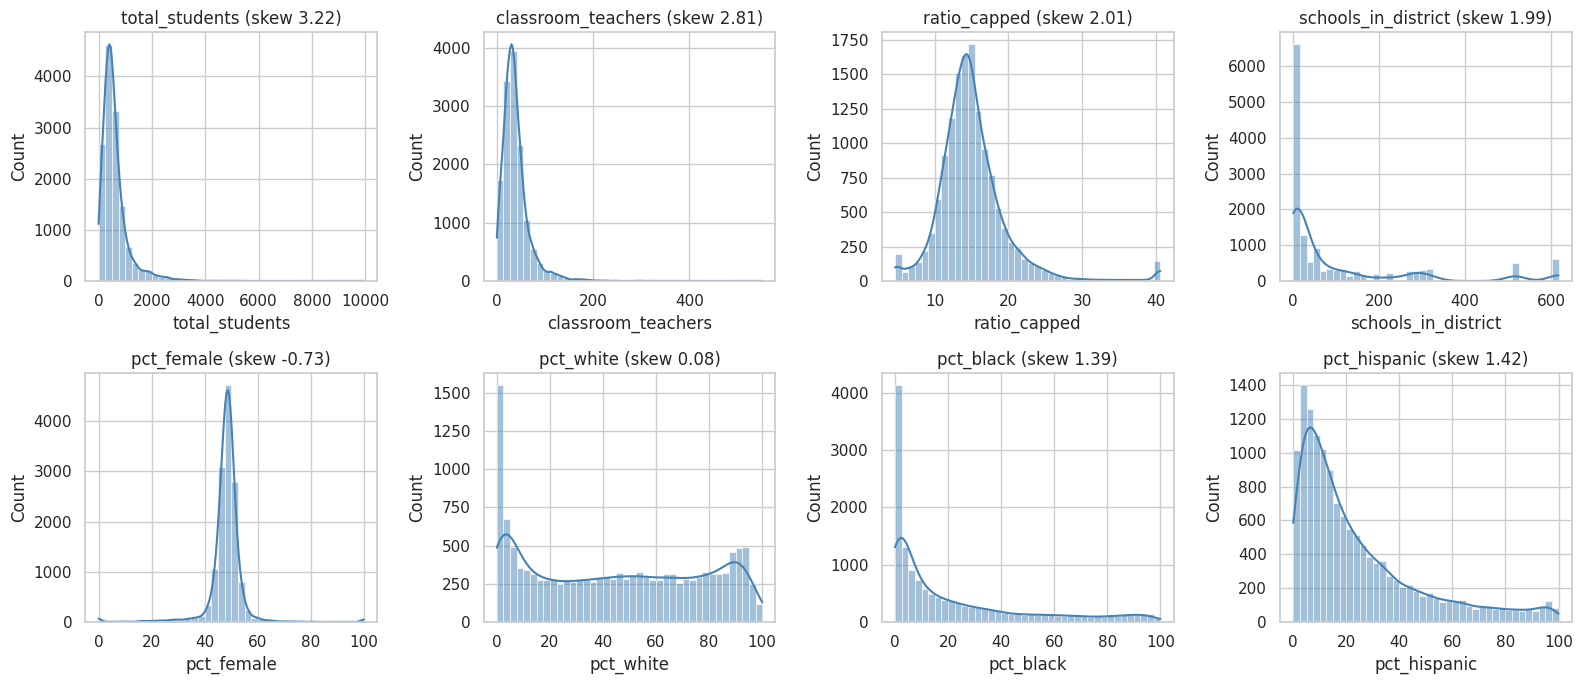

,skewness
total_students,3.22
classroom_teachers,2.81
ratio_capped,2.01
schools_in_district,1.99
pct_hispanic,1.42
pct_black,1.39
pct_white,0.08
pct_female,-0.73


In [55]:
skew_cols = ['total_students', 'classroom_teachers', 'ratio_capped', 'schools_in_district',
             'pct_female', 'pct_white', 'pct_black', 'pct_hispanic']
skew_table = df[skew_cols].skew().sort_values(ascending=False).round(2).to_frame('skewness')

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), skew_cols):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'{c} (skew {df[c].skew():.2f})')
plt.tight_layout(); plt.show()
skew_table

**Observations:** `total_students` (3.22), `classroom_teachers` (2.81), `ratio_capped` (2.01) and `schools_in_district` (1.99) are strongly right-skewed, meaning a few huge schools and districts pull the average up (mean 600 vs median 480 students). `pct_hispanic` and `pct_black` are also right-skewed, while `pct_white` is nearly symmetric.

                     skew_before  skew_after_log
total_students              3.22           -1.42
classroom_teachers          2.81           -1.04
schools_in_district         1.99            0.30


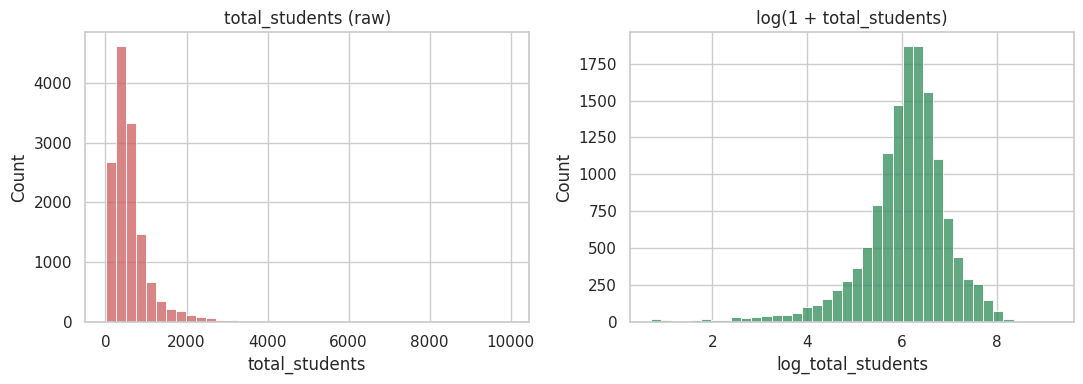

In [56]:
# Fix the heavy right skew with log(1 + x)
for c in ['total_students', 'classroom_teachers', 'schools_in_district']:
    df[f'log_{c}'] = np.log1p(df[c])

before = df[['total_students', 'classroom_teachers', 'schools_in_district']].skew()
after = df[['log_total_students', 'log_classroom_teachers', 'log_schools_in_district']].skew()
after.index = before.index
print(pd.DataFrame({'skew_before': before, 'skew_after_log': after}).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['total_students'], bins=40, ax=axes[0], color='indianred');     axes[0].set_title('total_students (raw)')
sns.histplot(df['log_total_students'], bins=40, ax=axes[1], color='seagreen'); axes[1].set_title('log(1 + total_students)')
plt.tight_layout(); plt.show()

**Observations:** The log transform brought the skew magnitude down for all three (students 3.22 to -1.42, teachers 2.81 to -1.04, schools per district 1.99 to 0.30). For students and teachers it slightly overshoots into a left skew, because there are many small schools. This is still much more balanced and better suited for models than the raw values.

#### B10. Correlation

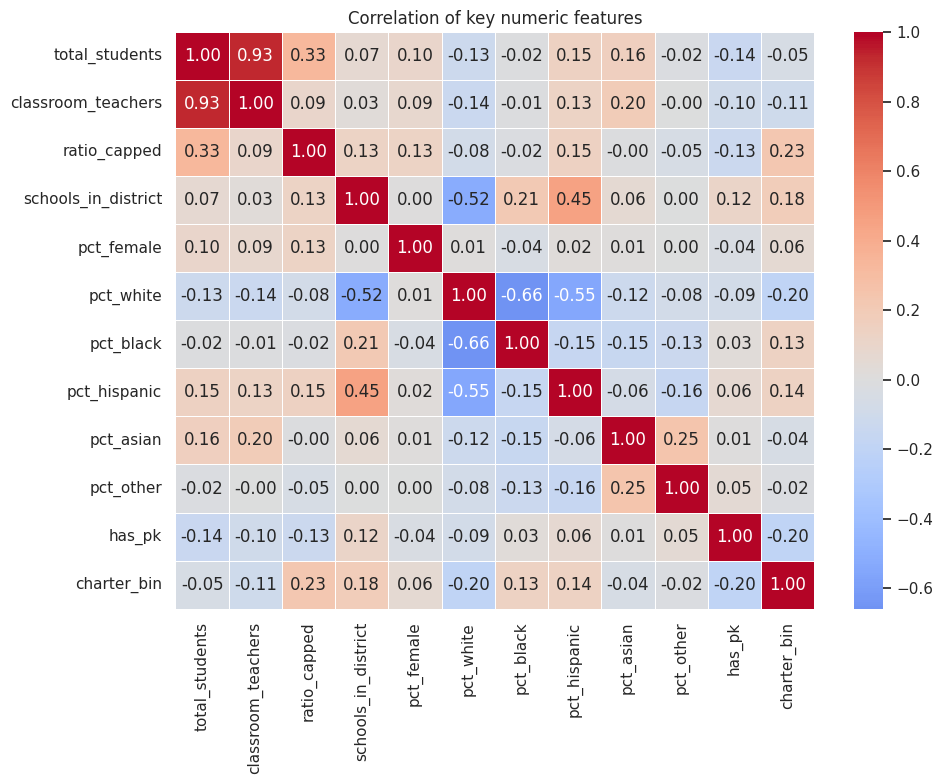

In [57]:
corr_cols = ['total_students', 'classroom_teachers', 'ratio_capped', 'schools_in_district', 'pct_female',
             'pct_white', 'pct_black', 'pct_hispanic', 'pct_asian', 'pct_other', 'has_pk', 'charter_bin']
plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Correlation of key numeric features'); plt.tight_layout(); plt.show()

**Observations:** Students and teachers are almost perfectly correlated (0.93), so they carry nearly the same information (keep an eye on this for modelling). `pct_white` moves opposite to `pct_black` (-0.66) and `pct_hispanic` (-0.55). Schools in larger districts have lower White share (-0.52) and higher Hispanic share (0.45). Student-teacher ratio rises with school size (0.33) and is higher for charter schools (0.23).

## 5. Preprocessing for Modelling

In [58]:
# Final readable dataset (keeps names, IDs, and all engineered columns)
drop_cols = ['mailing_address', 'physical_address', 'phone', 'state_school_id', 'state_district_id',
             'locale', 'grade_sum', 'gender_sum', 'race_sum']
df_clean = df.drop(columns=drop_cols).reset_index(drop=True)
print('Clean dataset:', df_clean.shape)

# Model-ready dataset
num_features = ['log_total_students', 'log_classroom_teachers', 'ratio_capped', 'log_schools_in_district',
                'pct_female', 'pct_white', 'pct_black', 'pct_hispanic', 'pct_asian', 'pct_other']
bin_features = ['charter_bin', 'has_pk', 'mailing_differs']
cat_features = ['school_type', 'school_level', 'locale_type', 'locale_size', 'state']

X_num = pd.DataFrame(StandardScaler().fit_transform(df_clean[num_features]), columns=num_features)
X_cat = pd.get_dummies(df_clean[cat_features], drop_first=True, dtype=int)
df_model = pd.concat([X_num, df_clean[bin_features], X_cat], axis=1)

print('Model-ready dataset:', df_model.shape, '| NaNs:', df_model.isna().sum().sum())
df_model.head()

Clean dataset: (13896, 57)
Model-ready dataset: (13896, 39) | NaNs: 0


,log_total_students,log_classroom_teachers,ratio_capped,log_schools_in_district,pct_female,pct_white,pct_black,pct_hispanic,pct_asian,pct_other,charter_bin,has_pk,mailing_differs,school_type_Regular school,school_type_Special education school,school_type_Vocational school,school_level_Elementary-Middle,school_level_High,school_level_Middle,school_level_Middle-High,school_level_Other / Combined,locale_type_Rural,locale_type_Suburban,locale_type_Town,locale_size_Fringe,locale_size_Large,locale_size_Midsize,locale_size_Remote,locale_size_Small,state_DE,state_FL,state_GA,state_HI,state_IA,state_ID,state_IL,state_IN,state_MD,state_OR
0,0.807483,0.642534,0.643868,-1.527423,0.369979,-1.174076,-0.597110,2.646975,-0.423499,-0.656367,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0
1,0.030168,-0.062046,0.038755,-1.527423,0.290944,-1.101023,1.759273,-0.321459,-0.422692,-0.157015,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0
2,0.169398,0.384729,-0.578575,-0.352889,-0.012339,0.189862,0.041236,-0.619889,0.353195,0.594166,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
3,1.239257,1.396715,0.032822,-0.129634,-0.061103,0.002728,0.350293,-0.688965,1.094293,-0.178580,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,-1.136309,-0.535646,-1.570359,-0.129634,-2.714347,0.165063,0.259547,-0.665006,0.720946,-0.250116,0,1,0,0,1,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0


In [59]:
# Quick proof that scaling worked: mean ~0, std ~1
df_model[num_features].agg(['mean', 'std']).round(3)

,log_total_students,log_classroom_teachers,ratio_capped,log_schools_in_district,pct_female,pct_white,pct_black,pct_hispanic,pct_asian,pct_other
mean,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Observations:** All scaled features have mean 0 and standard deviation 1, so no single feature dominates distance-based models. Note: for a real prediction task, fit the scaler on the training split only.

In [60]:
df_clean.to_csv('schools_clean.csv', index=False)
df_model.to_csv('schools_model_ready.csv', index=False)

# In Google Colab, uncomment to download:
# from google.colab import files
# files.download('schools_clean.csv'); files.download('schools_model_ready.csv')

print('Raw     :', df_raw.shape)
print('Clean   :', df_clean.shape)
print('Model   :', df_model.shape)

Raw     : (15000, 41)
Clean   : (13896, 57)
Model   : (13896, 39)
